<a href="https://colab.research.google.com/github/AmitabhTS/AML-LAB-EXPERIMENTS/blob/main/AMLEXP12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

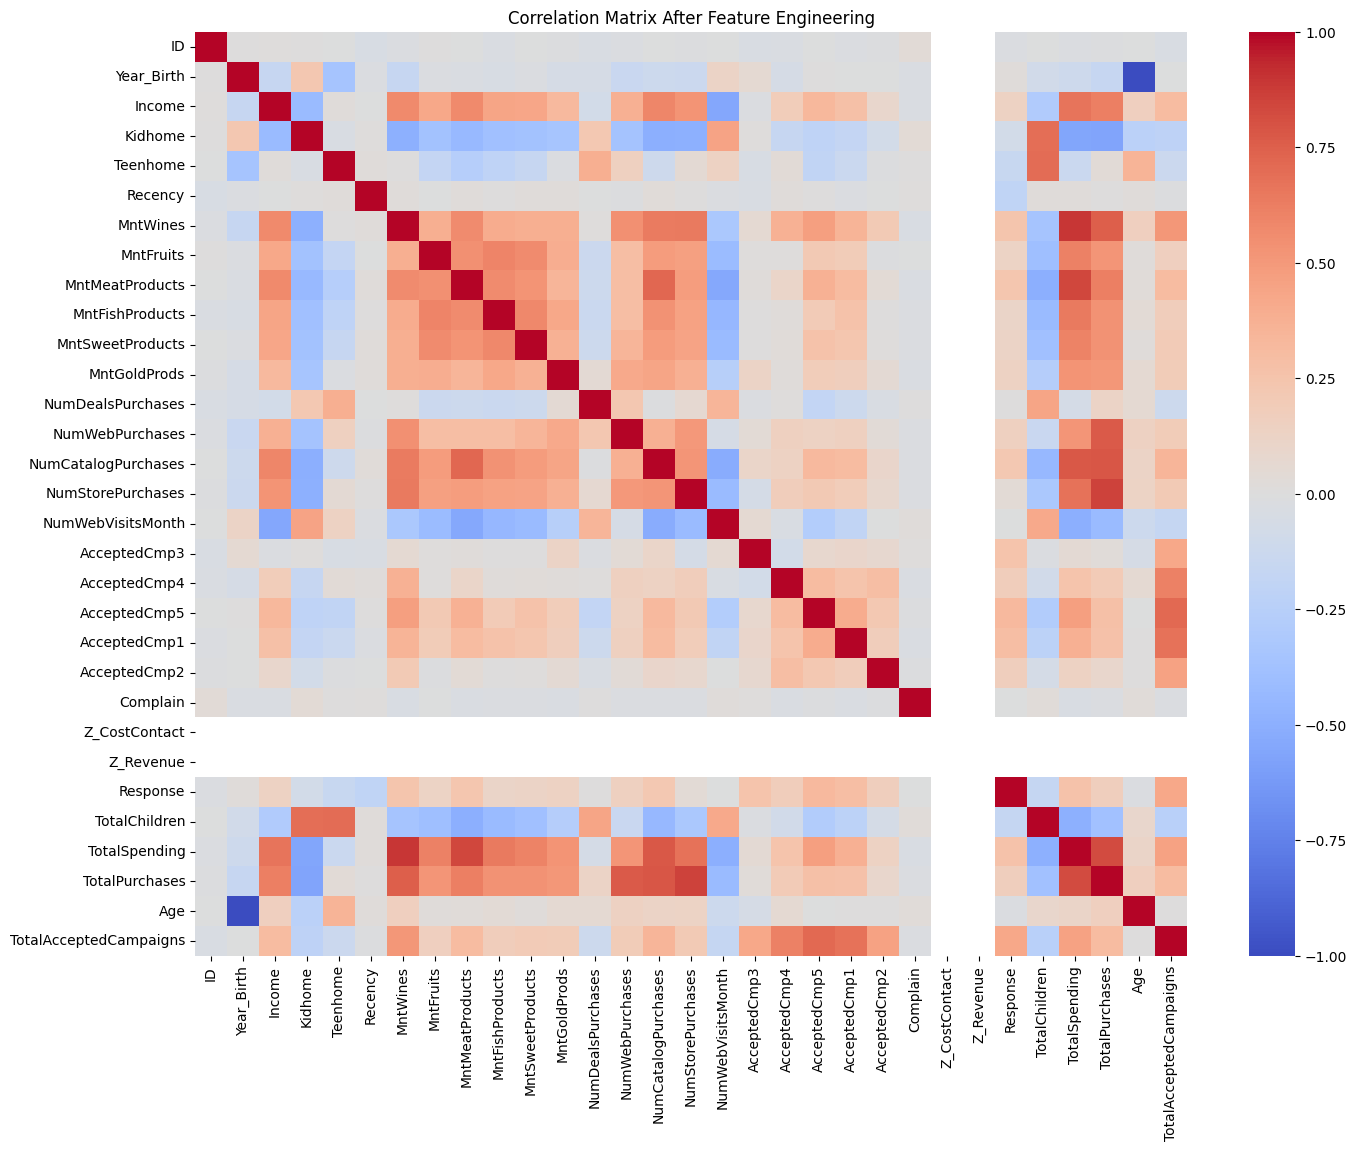

Response                  1.000000
TotalAcceptedCampaigns    0.426035
AcceptedCmp5              0.326634
AcceptedCmp1              0.293982
TotalSpending             0.265298
AcceptedCmp3              0.254258
MntWines                  0.247254
MntMeatProducts           0.236335
NumCatalogPurchases       0.220810
AcceptedCmp4              0.177019
AcceptedCmp2              0.169293
TotalPurchases            0.164688
NumWebPurchases           0.148730
MntGoldProds              0.139850
Income                    0.132867
MntFruits                 0.125289
MntSweetProducts          0.117372
MntFishProducts           0.111331
NumStorePurchases         0.039363
Year_Birth                0.021325
NumDealsPurchases         0.002238
Complain                 -0.001707
NumWebVisitsMonth        -0.003987
Age                      -0.021325
ID                       -0.021968
Kidhome                  -0.080008
Teenhome                 -0.154446
TotalChildren            -0.169163
Recency             

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

marketing_df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/AML/marketing_campaign_cleaned.csv", sep=",")

# Create total children
if {"Kidhome", "Teenhome"}.issubset(marketing_df.columns):
    marketing_df["TotalChildren"] = (
        marketing_df["Kidhome"] + marketing_df["Teenhome"]
    )

# Create total spending
spending_columns = [
    "MntWines",
    "MntFruits",
    "MntMeatProducts",
    "MntFishProducts",
    "MntSweetProducts",
    "MntGoldProds"
]

available_spending = [
    column for column in spending_columns
    if column in marketing_df.columns
]

if available_spending:
    marketing_df["TotalSpending"] = marketing_df[
        available_spending
    ].sum(axis=1)
# Create total purchases
purchase_columns = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases"
]

available_purchases = [
    column for column in purchase_columns
    if column in marketing_df.columns
]
if available_purchases:
    marketing_df["TotalPurchases"] = marketing_df[
        available_purchases
    ].sum(axis=1)
# Create age
if "Year_Birth" in marketing_df.columns:
    current_year = pd.Timestamp.now().year
    marketing_df["Age"] = (
        current_year - marketing_df["Year_Birth"]
    )
# Create total campaign responses
campaign_columns = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5"
]
available_campaigns = [
    column for column in campaign_columns
    if column in marketing_df.columns
]

if available_campaigns:
    marketing_df["TotalAcceptedCampaigns"] = marketing_df[
        available_campaigns
    ].sum(axis=1)
# Correlation matrix
numeric_df = marketing_df.select_dtypes(include="number")
corr = numeric_df.corr()
plt.figure(figsize=(16, 12))
sns.heatmap(
    corr,
    cmap="coolwarm",
    center=0,
    annot=False
)
plt.title("Correlation Matrix After Feature Engineering")
plt.show()
# Correlation with target
target_marketing = "Response"
if target_marketing in corr.columns:
    print(corr[target_marketing].sort_values(ascending=False))